# Hourly downscaling of AIFS-ENS over France

AIFS-ENS gives 2 m temperature every 6 hours on a 0.25° grid. [tutorial_inference.ipynb](tutorial_inference.ipynb)
adds the 5.5 km detail at those 6-hourly steps; this notebook also fills the five hours in between.
Interpolating linearly in time between two steps misses the shape of the daily cycle, and in
particular the warmest hour of the afternoon, which seldom falls on a 6-hourly step.

The hourly model is the spatial model's U-Net with two more inputs: the change of the coarse field
over the 6-hour window, and how far into the window the hour is. It starts from the spatial model's
weights, so before training it is the spatial model applied to the straight line, and it learned from
hourly CERRA (its analyses plus the +1 h and +2 h forecasts between them) how the hours bend away from
that line. Each member keeps its noise from one hour to the next, so its detail evolves smoothly.

- **a. Set up**: load both models from the Hub.
- **b. Fetch the forecast**: an AIFS-ENS run from ECMWF open data, no account needed.
- **c. Downscale every hour**: the spatial model on the straight line, and the hourly model.
- **d. Look at it**: maps at the warmest hour, one point hour by hour, and one member's smoothness.
- **e. Evaluate**: against the Météo-France stations, hour by hour.
- **f. Training**: how the published model was trained.

It runs in a few minutes on a CPU; an Apple or NVIDIA GPU, picked automatically, is quicker.

## a. Set up

Install as in [tutorial_inference.ipynb](tutorial_inference.ipynb) (`uv sync`). Nothing here needs an
account: the forecast comes from ECMWF's open data and the models and stations from the Hugging Face Hub.
The hourly model needs the spatial one as well, as the baseline it is compared with.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
from huggingface_hub import hf_hub_download

from downscale import hourly as hr
from downscale.constants import COARSE_CROP_MARGIN_DEG, ZERO_C
from downscale.evaluation import at_valid_times, lead_scores, pooled, stack_members
from downscale.inference import downscale_forecast, save_downscaled
from downscale.open_data import fetch_open_data
from downscale.plots import lead_figure, map_grid, native_cells, plume_figure
from downscale.regions import parse_region
from downscale.sources import forecast_box, save_forecast, store_name
from downscale.station_interp import curvilinear_for
from downscale.stations import load_published_stations

HOURLY_REPO = "kashif/france-temperature-hourly-downscaler"
SPATIAL_REPO = "EmmaScharfmann/france-temperature-downscaler"
STATIONS = "EmmaScharfmann/france-stations"   # Météo-France, hourly

INIT = pd.Timestamp("2025-08-10 00:00")   # the start of the August 2025 heatwave
MEMBERS = 10           # AIFS-ENS members, out of 51
MAX_LEAD_HOURS = 120   # five days
SAMPLES = 4            # downscaled maps per member: 10 members become 40
BOX = forecast_box(parse_region("france"), COARSE_CROP_MARGIN_DEG)
OUT = Path("outputs/tutorial_temporal")   # fetched and downscaled once, then read from here

hourly = hr.HourlyDownscaler.load(hf_hub_download(HOURLY_REPO, "model.pt"))
spatial = hr.load_spatial(hf_hub_download(SPATIAL_REPO, "model.pt"))
LAND = hourly.static["land_sea_mask"] > 0.5
print(f"fine grid {hourly.lat.shape[0]} x {hourly.lat.shape[1]} on {hourly.device}")
print("hourly model inputs:", hourly.net.cfg.channels)

/Users/kashif/Github/weather-forecast-model-downscaler/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


fine grid 228 x 238 on mps
hourly model inputs: ['era5_t2m', 'cerra_orography', 'orography_diff', 'land_sea_mask', 'lat', 'lon', 'coast_distance', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'tendency', 'offset']


## b. Fetch the forecast

`fetch_open_data` reads one AIFS-ENS run from ECMWF's open data on Google Cloud, keeping only the 2 m
temperature of the members asked for, cropped to France with a margin. It comes back 6-hourly, laid out
as the Earthmover archive is, so everything else in the repository can use it unchanged.

In [2]:
forecast_path = OUT / "forecasts" / store_name(INIT)
if not Path(str(forecast_path) + ".done").exists():
    save_forecast(fetch_open_data(INIT, BOX, members=MEMBERS, max_lead_hours=MAX_LEAD_HOURS), OUT / "forecasts")
coarse = xr.open_zarr(forecast_path)["t2m"].load()
print(dict(coarse.sizes), "every", int(np.diff(coarse.lead_time.values)[0] / np.timedelta64(1, "h")), "hours")

{'time': 1, 'lead_time': 20, 'ensemble': 10, 'lat': 65, 'lon': 85} every 6 hours


## c. Downscale every hour

`hourly_forecast` interpolates the coarse forecast linearly to every hour, from its first lead time to
the hour before its last: the straight line both models start from. Two forecasts are made from it:

- the **spatial model** applied to that line at every hour, which draws new noise every hour;
- the **hourly model**, given the two coarse steps around each hour, with each member's noise kept for
  the whole forecast.

In [3]:
coarse_hourly = hr.hourly_forecast(coarse)
leads = coarse_hourly.lead_time.values
paths = {name: OUT / name / store_name(INIT) for name in ("spatial", "hourly")}
if not paths["hourly"].exists():
    save_downscaled(downscale_forecast(spatial, coarse_hourly, samples=SAMPLES), paths["spatial"])
    save_downscaled(hr.downscale_hours(hourly, coarse, leads, samples=SAMPLES, batch=8), paths["hourly"])
runs = {name: xr.open_zarr(path) for name, path in paths.items()}
valid = pd.DatetimeIndex(runs["hourly"].valid_time.values[0])
print(f"{len(leads)} hours, {valid[0]:%d %b %H} UTC to {valid[-1]:%d %b %H} UTC;",
      {name: dict(ds.t2m_ds.sizes) for name, ds in runs.items()}["hourly"])

114 hours, 10 Aug 06 UTC to 14 Aug 23 UTC; {'time': 1, 'lead_time': 114, 'ensemble': 10, 'sample': 4, 'y': 228, 'x': 238}


## d. Look at it

### The warmest hour

On the second afternoon the warmest hour over land is between two 6-hourly steps. The straight line
between 12 and 18 UTC cannot reach the peak, and the spatial model, applied to that line, inherits its
timing. The hourly model knows the hour and how much the window warms, so it puts the peak back.

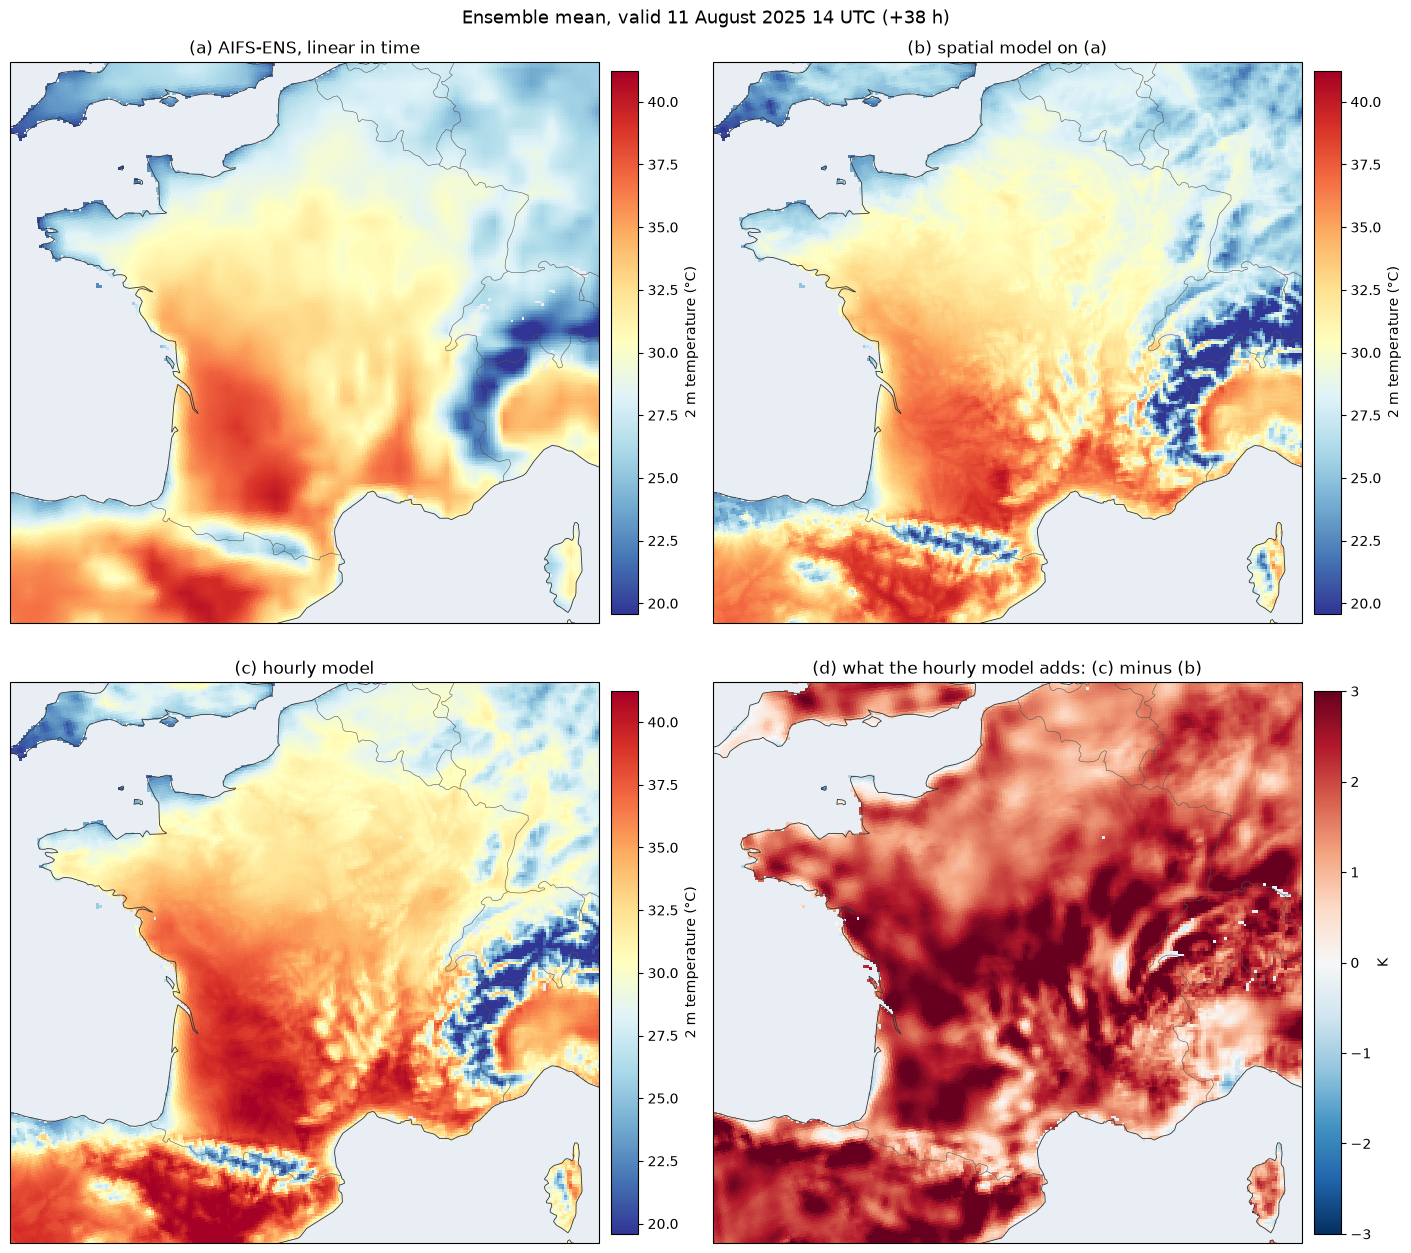

In [4]:
line = runs["hourly"].t2m_interp.isel(time=0).mean("ensemble") - ZERO_C   # (lead_time, y, x)
means = {name: stack_members(ds).isel(time=0).mean("member") - ZERO_C for name, ds in runs.items()}
day2 = (valid >= INIT + pd.Timedelta(hours=24)) & (valid < INIT + pd.Timedelta(hours=48))
k = int(np.flatnonzero(day2)[np.argmax(means["hourly"].values[day2][:, LAND].mean(1))])

on_land = lambda field: np.where(LAND, field, np.nan)
low, high = np.nanpercentile(on_land(means["hourly"].values[k]), [1, 99])
panel = dict(lon=hourly.lon, lat=hourly.lat, vmin=low, vmax=high, label="2 m temperature (°C)")
fig = map_grid([
    dict(title="(a) AIFS-ENS, linear in time", values=on_land(line.values[k]), **panel),
    dict(title="(b) spatial model on (a)", values=on_land(means["spatial"].values[k]), **panel),
    dict(title="(c) hourly model", values=on_land(means["hourly"].values[k]), **panel),
    dict(title="(d) what the hourly model adds: (c) minus (b)", lon=hourly.lon, lat=hourly.lat,
         values=on_land(means["hourly"].values[k] - means["spatial"].values[k]), cmap="RdBu_r",
         vmin=-3, vmax=3, label="K"),
], title=f"Ensemble mean, valid {valid[k]:%d %B %Y %H} UTC (+{int((valid[k] - INIT) / pd.Timedelta(hours=1))} h)")

### One point, hour by hour

At a station, the ensemble mean of each forecast against what was observed every hour. The black dots
are the 6-hourly steps AIFS-ENS actually provides.

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 2031.42it/s]

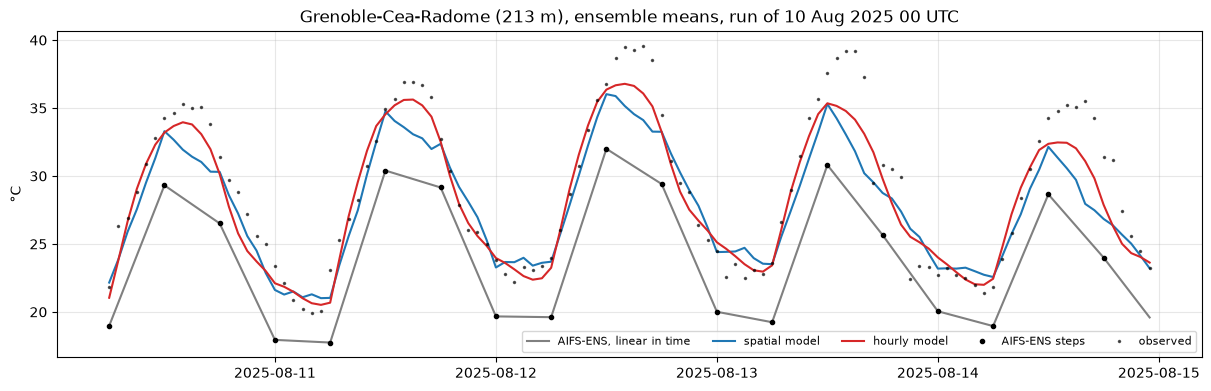

In [5]:
stations = load_published_stations(STATIONS, start=str(valid[0].date()), end=str(valid[-1].date()))
site = stations.sel(station=["38185012"])   # GRENOBLE-CEA-RADOME, at the bottom of a deep valley
read_site = curvilinear_for(hourly.lat, hourly.lon, site).apply
at_site = {
    "AIFS-ENS, linear in time": coarse_hourly.isel(time=0).interp(
        lat=float(site.latitude[0]), lon=float(site.longitude[0])).mean("ensemble").values - ZERO_C,
    **{f"{name} model": read_site(means[name] + ZERO_C).isel(station=0).values - ZERO_C for name in runs},
}
observed_site = site.t2m.isel(station=0).reindex(time=valid).values - ZERO_C

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3.8), constrained_layout=True)
for (name, values), colour in zip(at_site.items(), ("0.5", "tab:blue", "tab:red")):
    ax.plot(valid, values, color=colour, label=name)
steps = (valid - INIT) % pd.Timedelta(hours=6) == pd.Timedelta(0)
ax.plot(valid[steps], at_site["AIFS-ENS, linear in time"][steps], "ko", ms=3, label="AIFS-ENS steps")
ax.plot(valid, observed_site, "k.", ms=3, alpha=0.6, label="observed")
ax.set_ylabel("°C")
ax.set_title(f"{site['name'].item().title()} ({int(site.elevation[0])} m), ensemble means, run of {INIT:%d %b %Y %H} UTC")
ax.legend(fontsize=8, ncol=5)
ax.grid(alpha=0.3)

### One member is smooth in time

A single member, not the mean: the spatial model draws new noise every hour, so its detail jumps from
one hour to the next; the hourly model keeps it. The right panel shows the change from one hour to the
next at the same point: the observed one follows the daily cycle, the hourly member follows it too, and
the spatial member jumps around it by a few degrees.

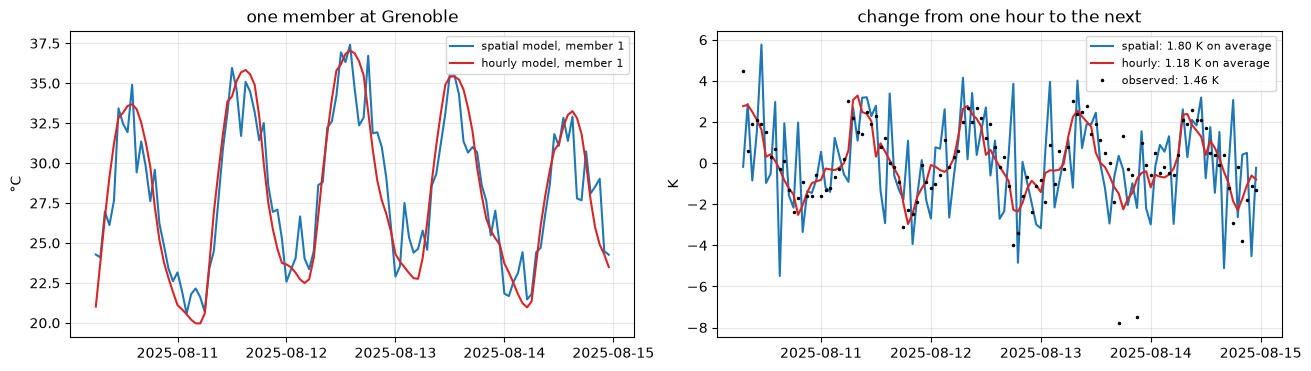

In [6]:
member = {name: read_site(ds.t2m_ds.isel(time=0, ensemble=0, sample=0)).isel(station=0).values - ZERO_C
          for name, ds in runs.items()}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), constrained_layout=True)
for name, colour in (("spatial", "tab:blue"), ("hourly", "tab:red")):
    ax[0].plot(valid, member[name], color=colour, label=f"{name} model, member 1")
    ax[1].plot(valid[1:], np.diff(member[name]), color=colour,
               label=f"{name}: {np.abs(np.diff(member[name])).mean():.2f} K on average")
ax[1].plot(valid[1:], np.diff(observed_site), "k.", ms=3, label=f"observed: {np.nanmean(np.abs(np.diff(observed_site))):.2f} K")
ax[0].set_title("one member at Grenoble")
ax[1].set_title("change from one hour to the next")
for a in ax:
    a.set_ylabel("°C" if a is ax[0] else "K")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)

## e. Evaluate against the stations

Every hour of the five days, at about 1,800 Météo-France stations, which neither model saw. Each forecast
is read at the stations from its own grid; the scores are those of
[tutorial_inference.ipynb](tutorial_inference.ipynb): RMSE of the ensemble mean, fair CRPS of the whole
ensemble, and the spread-skill ratio. AIFS-ENS linear in time has 10 members, the two downscaled
forecasts 40.

,"AIFS-ENS, linear in time",spatial model,hourly model
rmse_K,3.203,2.962,2.564
bias_K,0.013,-0.132,0.140
crps_K,2.018,1.735,1.447
spread_K,1.238,1.685,1.604


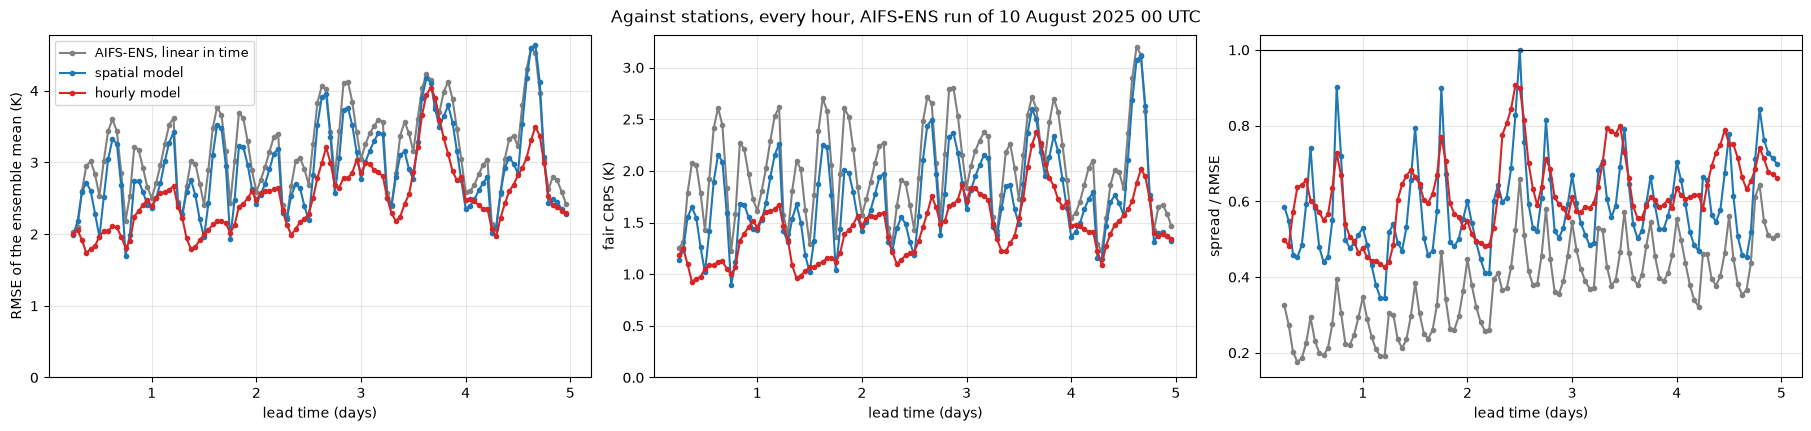

In [7]:
read = curvilinear_for(hourly.lat, hourly.lon, stations).apply
observed = at_valid_times(stations.t2m, runs["hourly"].valid_time)   # (time, lead_time, station)
forecasts = {
    "AIFS-ENS, linear in time": runs["hourly"].t2m_interp.rename(ensemble="member"),
    "spatial model": stack_members(runs["spatial"]),
    "hourly model": stack_members(runs["hourly"]),
}
COLOURS = {"AIFS-ENS, linear in time": "0.5", "spatial model": "tab:blue", "hourly model": "tab:red"}
scores = {name: lead_scores(read(forecast.load()), observed) for name, forecast in forecasts.items()}
fig = lead_figure(scores, metrics=("rmse_K", "crps_K", "spread_skill"), colours=COLOURS,
                  title=f"Against stations, every hour, AIFS-ENS run of {INIT:%d %B %Y %H} UTC")
pd.DataFrame({name: pooled(table) for name, table in scores.items()}).round(3)

The linear and spatial forecasts get worse and better again every six hours. Pooling the five days by
hour after the 6-hourly step shows why: they are best on the steps, where the straight line is the
forecast itself, and worst in the middle of the window.

,"AIFS-ENS, linear in time",spatial model,hourly model
hours after the step,,,
0,1.545,1.348,1.403
1,1.766,1.506,1.398
2,2.163,1.845,1.433
3,2.335,1.997,1.452
4,2.282,1.966,1.493
5,2.016,1.747,1.503


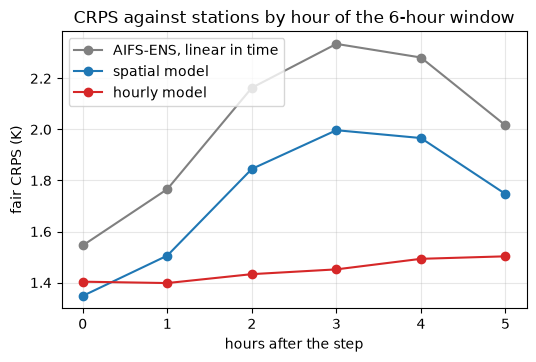

In [8]:
by_hour = pd.DataFrame({
    name: [pooled(table[table.lead_hours % 6 == k])["crps_K"] for k in range(6)] for name, table in scores.items()
}, index=pd.Index(range(6), name="hours after the step"))
ax = by_hour.plot(marker="o", color=[COLOURS[name] for name in by_hour], figsize=(6, 3.6),
                  title="CRPS against stations by hour of the 6-hour window")
ax.set_ylabel("fair CRPS (K)")
ax.grid(alpha=0.3)
by_hour.round(3)

The hourly model is nearly flat across the window, at about 1.4 to 1.5 K. On the step itself it is a
little behind the spatial model (1.40 against 1.35 K); everywhere in between it is ahead.

The [model card](https://huggingface.co/kashif/france-temperature-hourly-downscaler) scores the same run
with `scripts/eval_downscaled.py`, which applies station quality control and covers six more hours, so
its numbers differ a little; it also has a movie of the whole forecast.

## f. Training

The published model was trained with the scripts and `config_temporal.yaml`, which extends
`config_spatial.yaml` and lists only what the hourly model changes. Hourly CERRA needs a Copernicus
account; ERA5 is read from Google's public copy, which needs none.

```bash
uv run python scripts/download_cerra.py --config config_temporal.yaml          # 2019 and late July 2020, every hour
uv run python scripts/build_pairs.py --config config_temporal.yaml
# 1. from the spatial model, plain CRPS; the best epoch (8) is kept
uv run python scripts/train_downscaler.py --config config_temporal.yaml --temporal --out runs/hourly
# 2. continued with CRPS on block averages too, against grain from the noise
uv run python scripts/train_downscaler.py --config config_temporal.yaml --temporal \
    --init-hourly runs/hourly/model.pt --multiscale 2 4 8 16 --epochs 6 --learning-rate 3e-4 --out runs/hourly_ms
uv run python scripts/check_spectrum.py --config config_temporal.yaml --model runs/spatial/model.pt --hourly runs/hourly_ms/model.pt
```

To downscale other runs and animate one:

```bash
uv run python scripts/fetch_forecasts.py --config config_temporal.yaml --start 2025-08-10T00 --end 2025-08-10T00
uv run python scripts/downscale_hourly.py --config config_temporal.yaml --hourly runs/hourly_ms/model.pt --spatial runs/spatial/model.pt
uv run python scripts/movie_hourly.py --config config_temporal.yaml --stations
```